In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.options.display.max_rows = 627920

# Reading the Data

In [2]:
shopper_intention = pd.read_csv('online_shoppers_intention.csv')
shopper_intention.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [3]:
shopper_intention.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
# "Administrative", "Informational", "Product Related" represent the number of different types of pages visted by the visitor in that session
# "... Duration" represent the total time spent in each of these page categories
# "Bounce Rate" is the percentage of visitors who enter the site from that page and then leave ("bounce") without triggereing any other requests to the analytics server during that session
# "Exit Rate" is all pageviews to the page, percentage that were in the last in the session
# "Page Value" is the average value for a web page that a user visited before completing an e-commerce transaction
# "Special Day" indicates closeness of the site visiting time to a specific special day (e.g. Mother's Day, Valentine's Day), sessions are more likely to be finalized with transaction


# Finding Possible Relationships/Trends

### Shopping Sessions Relative to Total Sessions per Month

In [5]:
counts = (
    shopper_intention.groupby("Month")
    .size()
    .rename("observations")
    .reset_index()
)

revenue = (
    shopper_intention.groupby("Month")["Revenue"]
    .sum()
    .rename("total_revenue")
    .reset_index()
)

Shopping_months = counts.merge(
    revenue,
    on="Month",
    how="inner",
    validate="one_to_one"
)

order = [2, 5, 6, 4, 3, 0, 9, 8, 7, 1]

shopping_months_order = Shopping_months.reindex(order)
shopping_months_order

,Month,observations,total_revenue
2,Feb,184,3
5,Mar,1907,192
6,May,3364,365
4,June,288,29
3,Jul,432,66
0,Aug,433,76
9,Sep,448,86
8,Oct,549,115
7,Nov,2998,760
1,Dec,1727,216


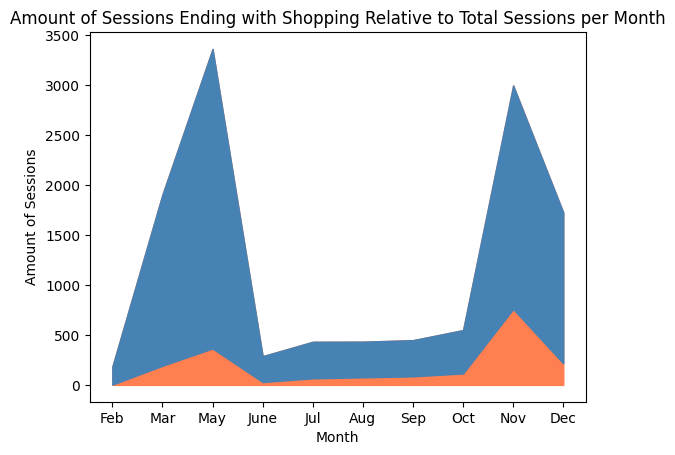

In [6]:
x = shopping_months_order["Month"]
total_sessions = shopping_months_order["total_revenue"]
purchases = shopping_months_order["observations"]

plt.fill_between(
    x, 
    0, 
    purchases, 
    color = "coral"
)
plt.fill_between(
    x, 
    purchases, 
    total_sessions, 
    color = "steelblue"
)
plt.title("Amount of Sessions Ending with Shopping Relative to Total Sessions per Month")
plt.xlabel("Month")
plt.ylabel("Amount of Sessions")
plt.show()

### Revenue per Region

### Distance to 'Special Day'

In [7]:
Special_day = (
    shopper_intention.groupby("Month")["SpecialDay"]
    .mean()
    .rename("Closeness to Special Day")
    .reset_index()
)

Special_day_shopping = counts.merge(
    Special_day, 
    on = "Month", 
    how = "inner", 
    validate = "one_to_one"
)

Special_day_shopping_order = Special_day_shopping.reindex(order)
Special_day_shopping_order


,Month,observations,Closeness to Special Day
2,Feb,184,0.233696
5,Mar,1907,0.000000
6,May,3364,0.212366
4,June,288,0.000000
3,Jul,432,0.000000
0,Aug,433,0.000000
9,Sep,448,0.000000
8,Oct,549,0.000000
7,Nov,2998,0.000000
1,Dec,1727,0.000000


In [8]:
shopper_intention[shopper_intention['SpecialDay'] > 0].groupby('Month').count()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
Month,,,,,,,,,,,,,,,,,
Feb,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79,79
May,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172,1172


In [14]:
shopper_intention[shopper_intention['Revenue'] == True].describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000,1908.000000
mean,3.393606,119.483244,0.786164,57.611427,48.210168,1876.209615,0.005117,0.019555,27.264518,0.023166,2.092767,2.453354,3.082285,4.021488
std,3.730527,201.114732,1.521176,171.619131,58.267365,2312.214392,0.012185,0.016463,35.191954,0.123521,0.929779,1.897042,2.407173,3.987140
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,15.000000,541.906250,0.000000,0.009521,3.641144,0.000000,2.000000,2.000000,1.000000,2.000000
50%,2.000000,52.366667,0.000000,0.000000,29.000000,1109.906250,0.000000,0.016000,16.758134,0.000000,2.000000,2.000000,2.000000,2.000000
75%,5.000000,151.083333,1.000000,19.000000,57.000000,2266.011310,0.006452,0.025000,38.897742,0.000000,2.000000,2.000000,4.000000,4.000000
max,26.000000,2086.750000,12.000000,1767.666667,534.000000,27009.859430,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [15]:
shopper_intention[shopper_intention['Revenue'] == False].describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000,10422.000000
mean,2.117732,73.740111,0.451833,30.236237,28.714642,1069.987809,0.025317,0.047378,1.975998,0.068432,2.129726,2.339474,3.159278,4.078392
std,3.202481,171.017970,1.211582,133.909306,40.744717,1803.797757,0.051877,0.051231,9.072424,0.209054,0.907835,1.681790,2.400493,4.032220
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,6.000000,151.000000,0.000000,0.015560,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,0.000000,0.000000,0.000000,0.000000,16.000000,510.190000,0.004255,0.028571,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,3.000000,83.000000,0.000000,0.000000,35.000000,1331.816667,0.020000,0.053846,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,246.758590,1.000000,8.000000,13.000000,9.000000,20.000000
